In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("bank-full.csv", sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head(10)

Dataset loaded successfully!
Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


In [22]:

# Display column names and data types
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check for 'unknown' entries in categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "category", "str"]
).columns

print("\nUnknown values:")
for col in categorical_cols:
    count = df[col].astype("string").str.lower().eq("unknown").sum()
    if count > 0:
        print(f"{col}: {count}")

# Check for duplicate records
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Examine the target distribution
print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget percentages:")
print((df["y"].value_counts(normalize=True) * 100).round(2))


Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y       

In [4]:
# Display all column names
print("Column names:")
print(df.columns.tolist())

# Display data types and non-null counts
df.info()

# Statistical summary of numerical columns
df.describe()

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


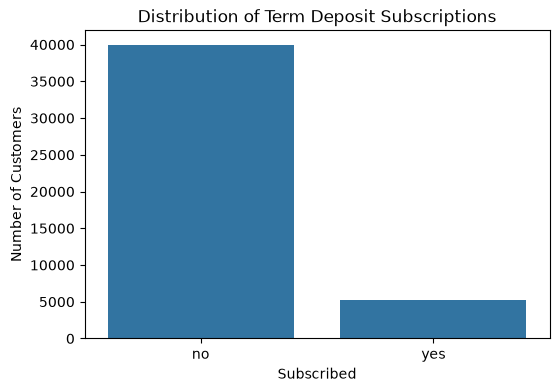

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="y")
plt.title("Distribution of Term Deposit Subscriptions")
plt.xlabel("Subscribed")
plt.ylabel("Number of Customers")
plt.show()

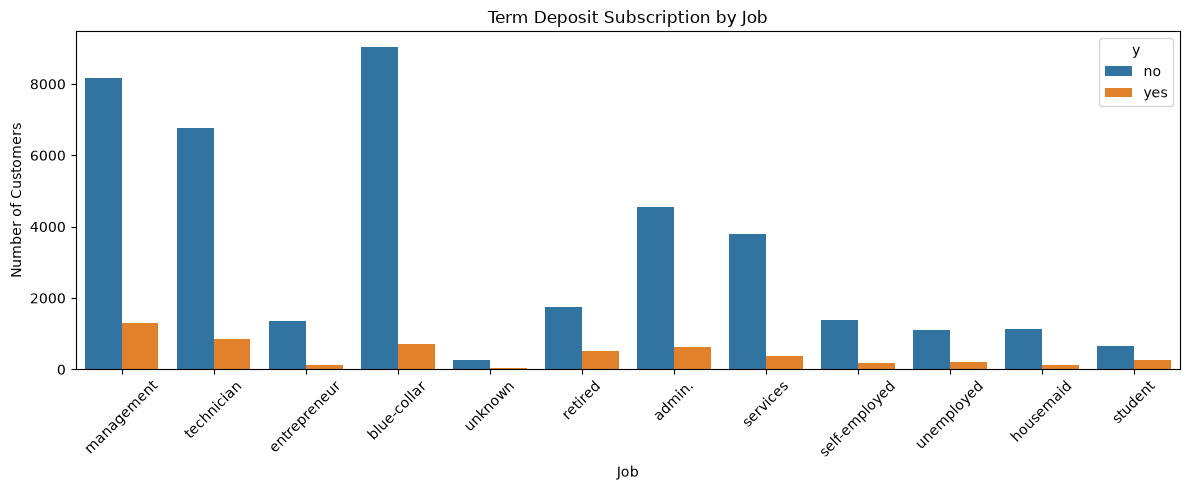

In [6]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="job", hue="y")
plt.title("Term Deposit Subscription by Job")
plt.xlabel("Job")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

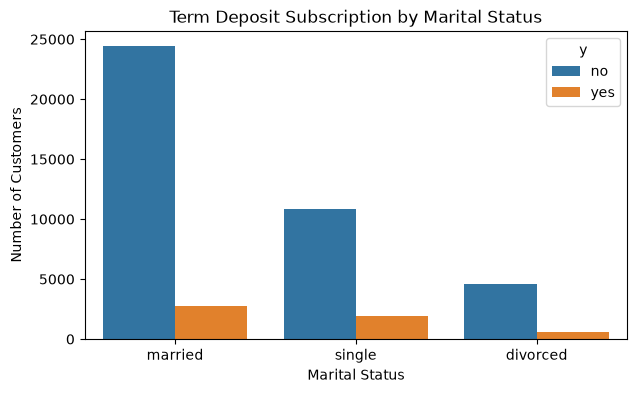

In [7]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="marital", hue="y")
plt.title("Term Deposit Subscription by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")
plt.show()

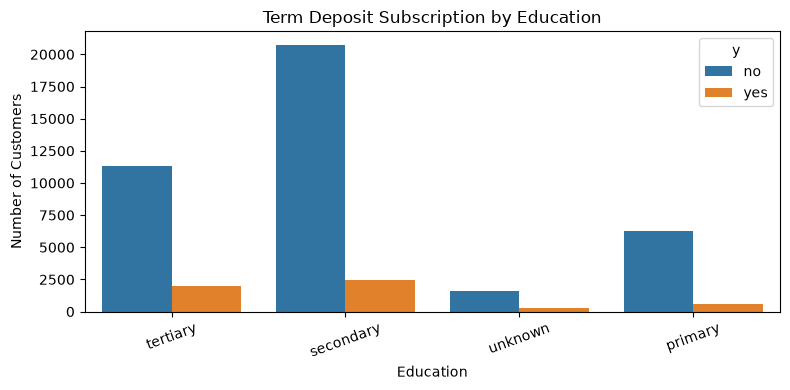

In [8]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="education", hue="y")
plt.title("Term Deposit Subscription by Education")
plt.xlabel("Education")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [23]:

# Subscription rate by job
job_rates = pd.crosstab(
    df["job"], df["y"], normalize="index"
) * 100

print("Subscription rate by job (%):")
display(job_rates.round(2))


Subscription rate by job (%):


y,no,yes
job,,
admin.,87.80,12.20
blue-collar,92.73,7.27
entrepreneur,91.73,8.27
housemaid,91.21,8.79
management,86.24,13.76
retired,77.21,22.79
self-employed,88.16,11.84
services,91.12,8.88
student,71.32,28.68


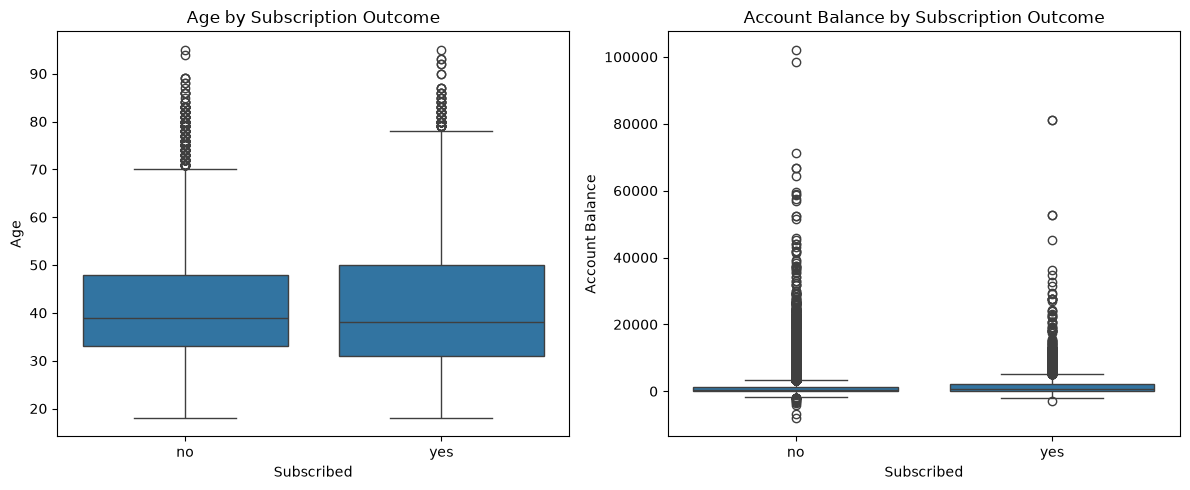

In [24]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="y", y="age", ax=axes[0])
axes[0].set_title("Age by Subscription Outcome")
axes[0].set_xlabel("Subscribed")
axes[0].set_ylabel("Age")

sns.boxplot(data=df, x="y", y="balance", ax=axes[1])
axes[1].set_title("Account Balance by Subscription Outcome")
axes[1].set_xlabel("Subscribed")
axes[1].set_ylabel("Account Balance")

plt.tight_layout()
plt.show()


In [9]:
# Separate input features and target
X = df.drop("y", axis=1)
y = df["y"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.unique())

Features shape: (45211, 16)
Target shape: (45211,)

Target classes:
<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str


In [10]:
X = X.drop("duration", axis=1)

print("Features after dropping duration:", X.shape)

Features after dropping duration: (45211, 15)


In [11]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessor created successfully!")
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Preprocessor created successfully!
Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [12]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop("y", axis=1)

# Exclude call duration from the primary model
X = X.drop("duration", axis=1)

y = df["y"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (36168, 15)
Testing features: (9043, 15)
Training target: (36168,)
Testing target: (9043,)


In [13]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Define the four classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

# Train each model with its own preprocessing pipeline
models = {}

for name, classifier in classifiers.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

        pipeline.fit(X_train, y_train)
    models[name] = pipeline

    print(f"{name} trained successfully!")


Logistic Regression trained successfully!
Decision Tree trained successfully!
KNN trained successfully!
Random Forest trained successfully!


In [14]:

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, pipeline in models.items():

    # Predict target labels
    y_pred = pipeline.predict(X_test)

    # Get probability of the positive class: "yes"
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="yes", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="yes", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "yes").astype(int), y_prob
        )
    })

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df.round(4))


Model Evaluation Results:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8933,0.6632,0.1786,0.2815,0.7717
1,Decision Tree,0.8309,0.2982,0.3289,0.3128,0.6132
2,KNN,0.8874,0.5529,0.1975,0.2911,0.7027
3,Random Forest,0.8954,0.6373,0.2457,0.3547,0.7888


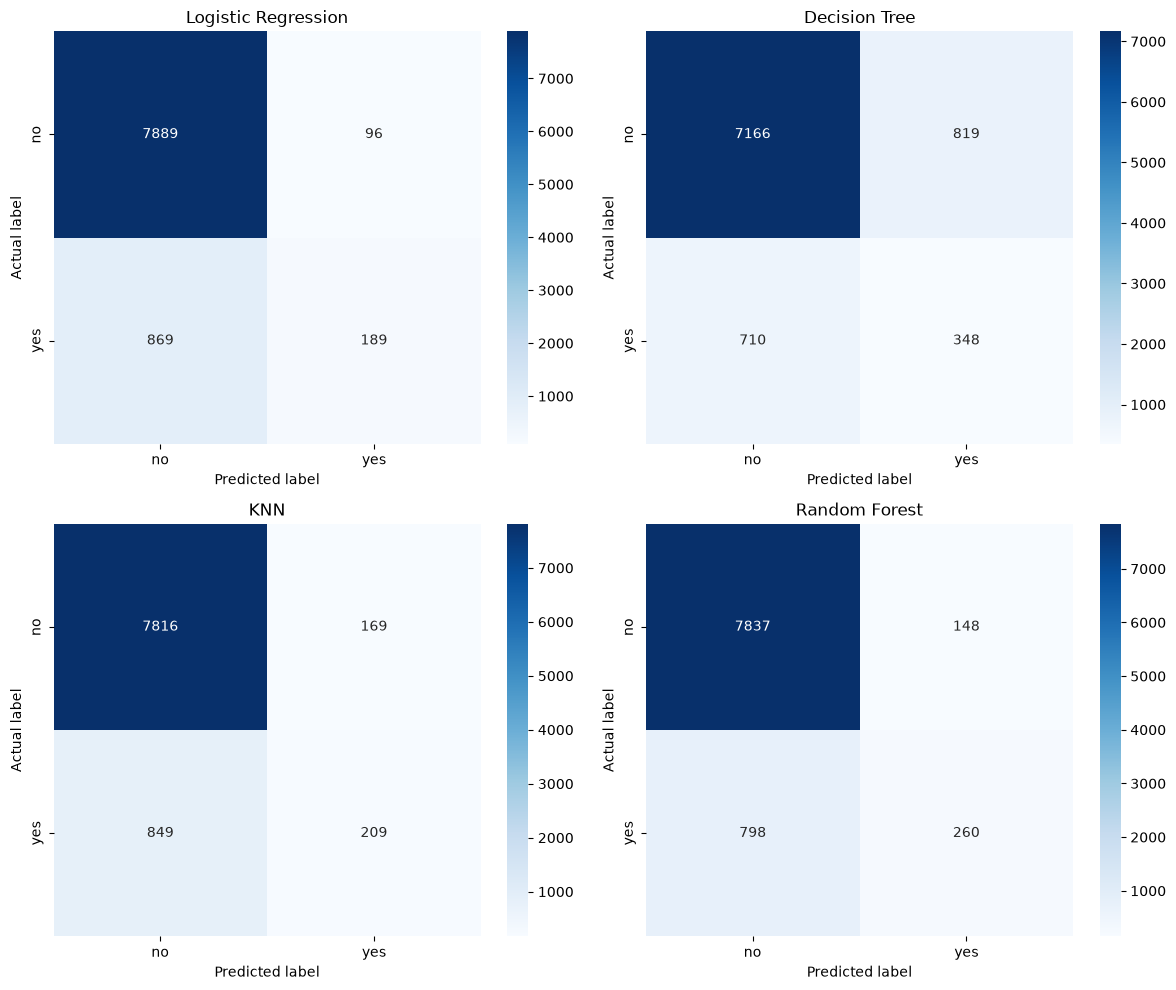

In [15]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, pipeline) in zip(axes, models.items()):

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["no", "yes"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["no", "yes"],
        yticklabels=["no", "yes"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()


In [28]:
print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8933     0.6632  0.1786    0.2815   0.7717
      Decision Tree    0.8309     0.2982  0.3289    0.3128   0.6132
                KNN    0.8874     0.5529  0.1975    0.2911   0.7027
      Random Forest    0.8954     0.6373  0.2457    0.3547   0.7888


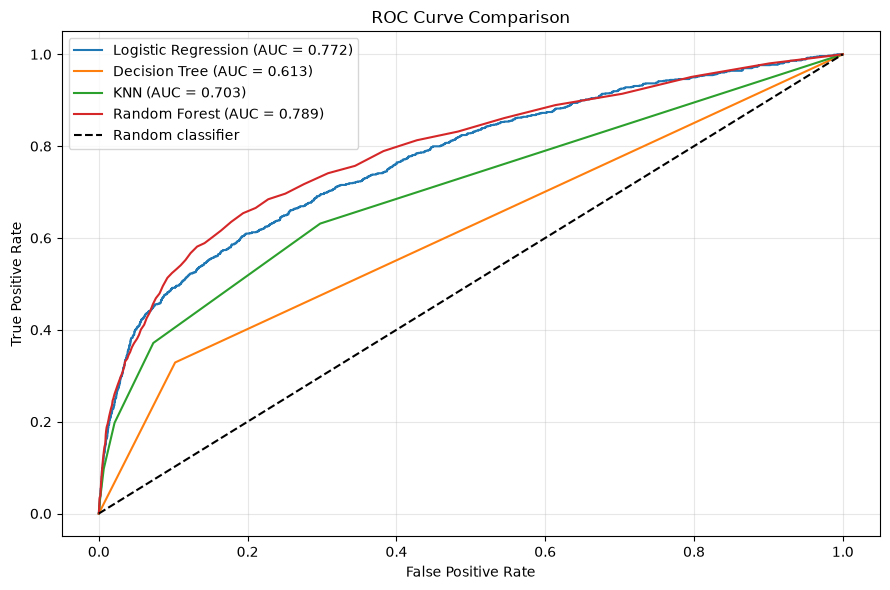

In [16]:

from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for name, pipeline in models.items():

    y_prob = pipeline.predict_proba(X_test)[:, 1]
    y_test_binary = (y_test == "yes").astype(int)

    fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob)
    auc = roc_auc_score(y_test_binary, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [26]:
best_model = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).iloc[0]

print("Model with the highest ROC-AUC:")
print(best_model)


Model with the highest ROC-AUC:
Model        Random Forest
Accuracy          0.895389
Precision         0.637255
Recall            0.245747
F1-Score          0.354707
ROC-AUC           0.788788
Name: 3, dtype: object


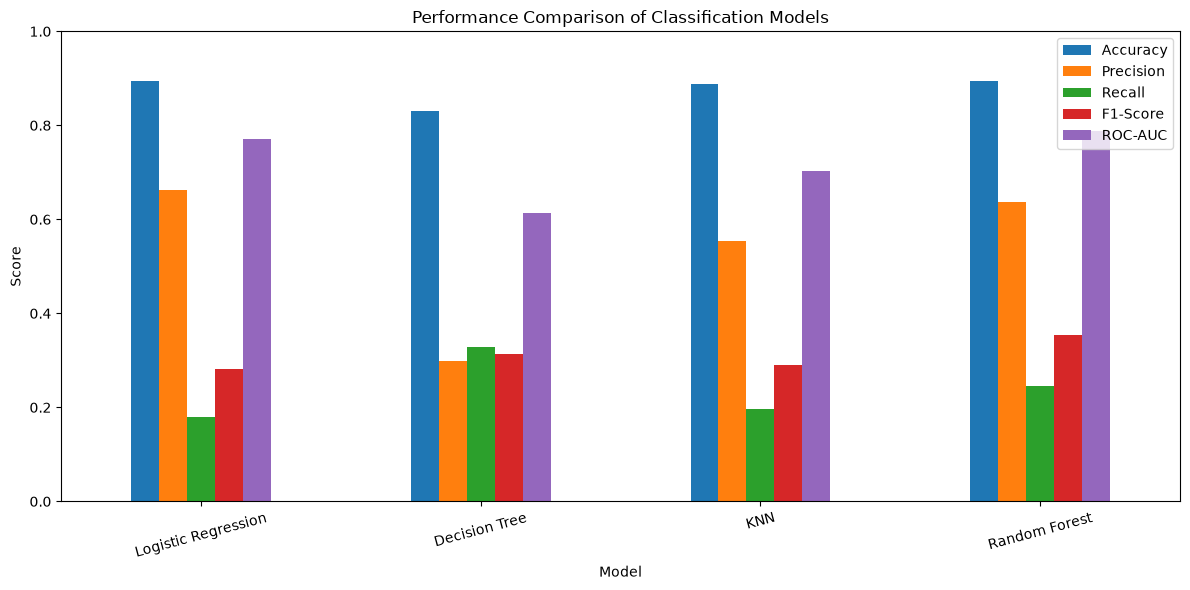

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

comparison = results_df.set_index("Model")[metrics]

comparison.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [19]:
for metric in metrics:
    best_row = results_df.loc[results_df[metric].idxmax()]
    print(f"\nBest model by {metric}:")
    print(f"  Model: {best_row['Model']}")
    print(f"  Score: {best_row[metric]:.4f}")


Best model by Accuracy:
  Model: Random Forest
  Score: 0.8954

Best model by Precision:
  Model: Logistic Regression
  Score: 0.6632

Best model by Recall:
  Model: Decision Tree
  Score: 0.3289

Best model by F1-Score:
  Model: Random Forest
  Score: 0.3547

Best model by ROC-AUC:
  Model: Random Forest
  Score: 0.7888


In [29]:
# Subscription rate by job
job_rates = pd.crosstab(df["job"], df["y"], normalize="index") * 100
print("Subscription rate by job:")
display(job_rates.round(2))

# Subscription rate by marital status
marital_rates = pd.crosstab(df["marital"], df["y"], normalize="index") * 100
print("Subscription rate by marital status:")
display(marital_rates.round(2))

# Subscription rate by education
education_rates = pd.crosstab(df["education"], df["y"], normalize="index") * 100
print("Subscription rate by education:")
display(education_rates.round(2))

Subscription rate by job:


y,no,yes
job,,
admin.,87.80,12.20
blue-collar,92.73,7.27
entrepreneur,91.73,8.27
housemaid,91.21,8.79
management,86.24,13.76
retired,77.21,22.79
self-employed,88.16,11.84
services,91.12,8.88
student,71.32,28.68


Subscription rate by marital status:


y,no,yes
marital,,
divorced,88.05,11.95
married,89.88,10.12
single,85.05,14.95


Subscription rate by education:


y,no,yes
education,,
primary,91.37,8.63
secondary,89.44,10.56
tertiary,84.99,15.01
unknown,86.43,13.57


In [30]:
display(results_df.round(4))

best_model = results_df.sort_values(
    by="ROC-AUC", ascending=False
).iloc[0]

print("Best model by ROC-AUC:", best_model["Model"])
print("ROC-AUC:", round(best_model["ROC-AUC"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-score:", round(best_model["F1-Score"], 4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8933,0.6632,0.1786,0.2815,0.7717
1,Decision Tree,0.8309,0.2982,0.3289,0.3128,0.6132
2,KNN,0.8874,0.5529,0.1975,0.2911,0.7027
3,Random Forest,0.8954,0.6373,0.2457,0.3547,0.7888


Best model by ROC-AUC: Random Forest
ROC-AUC: 0.7888
Precision: 0.6373
Recall: 0.2457
F1-score: 0.3547


In [ ]:
### Best Model Selection and Justification

Based on the evaluation results, **Random Forest was selected as the best-performing model overall**. It achieved the highest ROC-AUC score of **0.7888**, indicating better discrimination between subscribers and non-subscribers than the other evaluated models. It also achieved the highest accuracy of **89.54%** and the highest F1-score of **0.3547**.

Random Forest obtained a precision of **0.6373**, meaning that approximately 63.73% of the customers predicted as subscribers were actual subscribers in the test set. However, its recall was only **0.2457**, meaning that it identified approximately 24.57% of all actual subscribers. Therefore, the model still misses many potential subscribers.

Although Logistic Regression achieved slightly higher precision (**0.6632**), Random Forest provided a better balance between precision and recall according to its higher F1-score, while also achieving the highest ROC-AUC.

Consequently, Random Forest is selected as the best overall model among the four tested algorithms. Further improvements, such as class weighting, resampling, and decision-threshold tuning, could be investigated to improve subscriber detection.